# CrusherBayes con retención en los diez muestreos: los intervalos predictivos frente a la banda de CrusherCal, lo que identifican los muestreos y el criterio de descarte aplicado tal como está escrito

**Pregunta:** ¿Predice CrusherBayes, la calibración bayesiana del motor con una discrepancia estructural, un muestreo retenido mejor que la recta de solo abertura B-lin y da un intervalo más estrecho y calibrado que la banda de CrusherCal, y el criterio escrito antes de la corrida lo conserva o lo descarta?

- **Nivel:** 4, el método propuesto por el producto
- **Requisitos previos:** los notebooks 01 y 02 de este tema y el notebook 04 del tema 06
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook usted puede:

- decir qué afirma CrusherBayes frente al punto único calibrado del artículo, y qué resultado lo descartaría, enunciado antes de la corrida;
- puntuar sus predicciones con retención y sus intervalos de 80 por ciento en los diez muestreos frente a B-lin, el modelo base, la regresión libre y la banda de CrusherCal;
- leer la tabla de contracción para decir qué parámetros identifican los diez muestreos y cuáles quedan en su a priori;
- aplicar el criterio de descarte con los números calculados aquí, compararlo con el veredicto versionado, y decir qué muestra el registro de convergencia.

## Preparación

Numpy y matplotlib; el módulo CrusherBayes se importa por su función del criterio de descarte, y su muestreador no se corre aquí (el notebook 02 lo corrió en vivo).

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son el lector de muestreos, el constructor del modelo base, las funciones de CrusherCal y el módulo CrusherBayes.

In [1]:

# Imprima las versiones de las herramientas de este notebook, para compararlas con
# notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas del pipeline: el notebook no define ningún método propio
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo, crusherbayes as cb
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500. Propietarios: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las filas están transcritas de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv`, `VERSION`, y `data/derived/hp500/crusherbayes.json`. Ese documento guarda el resultado de diez pliegues del muestreador de largo completo, once distribuciones a posteriori de 7000 pasos cada una, que se calcula fuera de línea y nunca se corre en un notebook; **los números de CrusherBayes de este notebook se leen de él y se puntúan aquí, y no son una corrida en vivo**. La banda de CrusherCal y los comparadores se calculan en vivo.

La celda lee los muestreos, construye en vivo el documento con retención de CrusherCal y carga el versionado.

In [2]:

# Los muestreos, el modelo base y el documento con retención de CrusherCal construido en vivo, y el
# documento versionado de CrusherBayes
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
crushercal = loo.build(backbone.build(surveys, version), version)
committed = json.loads((ROOT / "data/derived/hp500/crusherbayes.json").read_text(encoding="utf-8"))
record = committed["convergence"]["folds"]
text = (
    'muestreos: {} | etiqueta de versión: {} | cadenas versionadas: '
    '{} pasos, convergieron {} de {} a posteriori'
)
passed = sum(c["converged"] for c in record)
print(text.format(len(surveys), version, committed["method"]["steps"], passed, len(record)))


muestreos: 10 | etiqueta de versión: 0.12.001 | cadenas versionadas: 7000 pasos, convergieron 11 de 11 a posteriori


## Método

**La afirmación y la regla que la prueba.** La calibración de Rocha et al. (2024) es un ajuste puntual. CrusherBayes pone un a posteriori sobre los ocho escalares ajustados del motor, agrega una discrepancia estructural de bajo orden por objetivo (Kennedy y O'Hagan, 2001), y lo reajusta sin cada muestreo retenido. El documento de diseño enuncia la hipótesis y su criterio de descarte antes de la corrida: el método se descarta como predictor si (a) su error de potencia no es menor que el de B-lin en al menos 3 puntos y su error de tonelaje no supera al del modelo base por el mismo margen, y (b) en cualquiera de los objetivos su cobertura queda fuera de 0.7 a 0.9 o su banda es más ancha que la de CrusherCal. Tres puntos de MAPE es el margen porque con diez muestreos una diferencia menor es ruido. El documento de diseño pide la cobertura anidada y que la banda se compare a igual cobertura; el módulo lee la cobertura como la del propio intervalo a posteriori de CrusherBayes y la regla del ancho como una comparación directa de los dos anchos medios, con las coberturas informadas al lado (`cb.kill_criterion`). Aquí esa lectura no cambia nada, porque los dos métodos tienen la misma cobertura en cada objetivo, 0.8 en el tonelaje y 0.9 en la potencia, como imprimen las celdas de abajo. El notebook puntúa todo lo que la regla necesita, y luego aplica la regla.

**La banda de CrusherCal.** La banda de comparación es la que el producto ya entrega: la predicción con retención del modelo base más o menos 1.2816 veces el sigma anidado, en el que el sigma de cada muestreo sale de los residuos de los otros nueve (notebook 04 del tema 06). La celda la construye para ambos objetivos a partir del documento en vivo de CrusherCal.

In [3]:

# La banda de 80 por ciento de CrusherCal por muestreo: la predicción con retención del modelo base
# más o menos 1.2816 veces el sigma anidado
cc_band = {}
for name in cb.TARGETS:
    strict = crushercal["loo"][name]["strict"]
    measured = np.array(crushercal["loo"][name]["measured"])
    pred = np.array(strict["pred"]["M0"])
    nested = loo.nested_band_coverage(measured - pred)
    half = loo.band_factor(0.8) * np.array(nested["sigma"])
    cc_band[name] = (pred - half, pred + half)
    outside = (np.flatnonzero(~np.array(nested["covered"])) + 1).tolist()
    print(f"{name:5s} banda de CrusherCal: cobertura {nested['coverage']:.2f}, ancho medio {np.mean(2 * half):7.1f}, "
          f"muestreos fuera: {outside}")


tph   banda de CrusherCal: cobertura 0.80, ancho medio   473.8, muestreos fuera: [1, 6]
kW    banda de CrusherCal: cobertura 0.90, ancho medio   209.8, muestreos fuera: [7]


## Comparación

La celda siguiente puntúa a CrusherBayes en las mismas condiciones: la media predictiva a posteriori de cada muestreo retenido del documento versionado frente a la medición, la proporción de muestreos dentro de su propio intervalo de 80 por ciento, y el ancho medio de ese intervalo.

In [4]:

# Las predicciones con retención de CrusherBayes y sus intervalos de 80 por ciento, del documento
# versionado, puntuadas aquí
cb_score = {}
for name in cb.TARGETS:
    block = committed["loo"][name]
    measured = np.array(block["measured"])
    lo, hi = np.array(block["lo80"]), np.array(block["hi80"])
    inside = (measured >= lo) & (measured <= hi)
    mape = loo.mape(measured, np.array(block["pred_mean"]))
    cb_score[name] = {"mape": mape, "coverage": float(inside.mean()), "width": float(np.mean(hi - lo))}
    outside = (np.flatnonzero(~inside) + 1).tolist()
    print(f"{name:5s} CrusherBayes: MAPE {mape:5.2f} %, cobertura {inside.mean():.2f}, "
          f"ancho medio {np.mean(hi - lo):7.1f}, muestreos fuera: {outside}")


tph   CrusherBayes: MAPE 12.00 %, cobertura 0.80, ancho medio   439.1, muestreos fuera: [1, 3]
kW    CrusherBayes: MAPE 14.31 %, cobertura 0.90, ancho medio   117.7, muestreos fuera: [4]


La tabla pone el error con retención de CrusherBayes junto a los tres comparadores, que el notebook calcula del documento en vivo de CrusherCal con la misma función, y debajo la densidad predictiva logarítmica media de los valores retenidos, el puntaje que el documento de diseño enumera junto al error, leída del documento versionado.

In [5]:

# El MAPE con retención de CrusherBayes y de los comparadores sobre los mismos diez muestreos
comparator_mape = {}
print('objetivo  CrusherBayes   modelo base M0   B-lin   libre M2')
for name in cb.TARGETS:
    strict = crushercal["loo"][name]["strict"]
    measured = np.array(crushercal["loo"][name]["measured"])
    row = {m: loo.mape(measured, np.array(strict["pred"][m])) for m in ("M0", "B_lin", "M2")}
    comparator_mape[name] = row
    print(f"{name:6s} {cb_score[name]['mape']:11.2f} {row['M0']:15.2f} {row['B_lin']:9.2f} {row['M2']:10.2f}")
# La densidad predictiva logarítmica media de los valores retenidos, leída del documento (mayor es mejor)
print('densidad predictiva logarítmica media, del documento')
for name in cb.TARGETS:
    own = committed["loo"][name]["scores"]["lpd_mean"]
    lpd = {m: committed["comparators"][name][m]["lpd_mean"] for m in ("M0", "B_lin", "M2")}
    print(f"{name:6s} {own:11.3f} {lpd['M0']:15.3f} {lpd['B_lin']:9.3f} {lpd['M2']:10.3f}")


objetivo  CrusherBayes   modelo base M0   B-lin   libre M2
tph          12.00           12.09     13.67      12.18
kW           14.31           25.94     12.78      14.03
densidad predictiva logarítmica media, del documento
tph         -6.678          -6.896    -6.709     -6.647
kW          -5.346          -5.847    -5.341     -5.399


En el tonelaje CrusherBayes tiene un error de 12.00 por ciento, frente a 12.09 del modelo base, 12.18 de la regresión libre y 13.67 de B-lin: una ganancia de 0.09 puntos sobre el modelo base, muy dentro del margen de 3 puntos bajo el cual diez muestreos no distinguen métodos. En la potencia tiene 14.31 por ciento frente a 12.78 de B-lin, 14.03 de la regresión y 25.94 del modelo base. Supera al modelo base en potencia por 11.6 puntos, que es el término de discrepancia haciendo lo que el motor solo no puede, pero no supera a B-lin: está 1.53 puntos detrás de una recta sin física y con dos coeficientes. La densidad predictiva logarítmica dice lo mismo: en la potencia retenida CrusherBayes obtiene -5.346 frente a -5.341 de B-lin, -5.399 de la regresión y -5.847 del modelo base, a la par de la recta y muy por delante del modelo base. Esa es la afirmación que no gana, y el notebook la informa así.

La figura dibuja los intervalos. Para cada muestreo la barra gris es la banda de 80 por ciento de CrusherCal, la azul es la de CrusherBayes, y el punto rojo es la medición. Esa fila es la de potencia. En tonelaje la regresión libre queda levemente por delante de CrusherBayes en la tabla anterior, y la densidad de los comparadores es una gaussiana con el sigma anidado, una construcción distinta de la mezcla a posteriori de CrusherBayes, así que las dos no son estrictamente comparables.

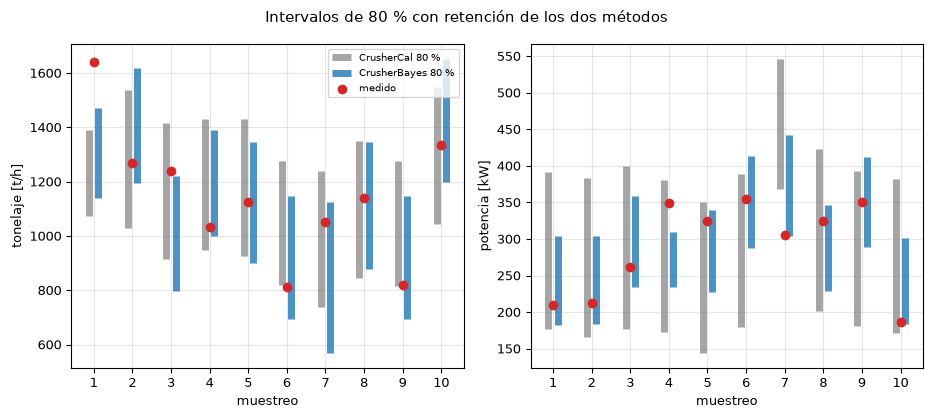

In [6]:

# Las diez predicciones con retención con el intervalo de CrusherBayes, la banda de CrusherCal y el
# valor medido
x = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.2))
for ax, name, ylabel in zip(axes, cb.TARGETS, ('tonelaje [t/h]', 'potencia [kW]')):
    block = committed["loo"][name]
    lo, hi = np.array(block["lo80"]), np.array(block["hi80"])
    cc_lo, cc_hi = cc_band[name]
    ax.vlines(x - 0.12, cc_lo, cc_hi, color="tab:grey", lw=5, alpha=0.7, label='CrusherCal 80 %')
    ax.vlines(x + 0.12, lo, hi, color="tab:blue", lw=5, alpha=0.8, label='CrusherBayes 80 %')
    ax.scatter(x, block["measured"], color="tab:red", zorder=3, label='medido')
    ax.set_xticks(x)
    ax.set_xlabel('muestreo')
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=7)
fig.suptitle('Intervalos de 80 % con retención de los dos métodos')
fig.tight_layout()
plt.show()


Los intervalos de CrusherBayes son más angostos que los de CrusherCal en ambos objetivos: un ancho medio de 439 t/h frente a 474 en el tonelaje (93 por ciento de la banda) y 118 kW frente a 210 en la potencia (56 por ciento). La cobertura de CrusherBayes es 0.8 en el tonelaje y 0.9 en la potencia (8 y 9 muestreos de 10 dentro): los muestreos 1 y 3 quedan fuera de su intervalo en el tonelaje y el muestreo 4 en la potencia, mientras la banda anidada de CrusherCal cubre 0.8 y 0.9. Con diez muestreos uno mueve la cobertura en 0.1, así que estas coberturas no se distinguen del 0.8 nominal y la figura no dice más de la calibración que el que es plausible. El estrechamiento en la potencia es una ganancia solo frente a la banda del modelo base. No hace que el intervalo de CrusherBayes sea apreciablemente más estrecho que el de un modelo más simple: las celdas de abajo dan a B-lin y a la regresión libre una banda propia, una banda anidada de sus residuos con retención, que es una construcción distinta de los cuantiles a posteriori de CrusherBayes.

La misma regla de banda de residuos que fija la banda de CrusherCal se puede aplicar a los propios residuos con retención de CrusherBayes, para preguntar si el intervalo a posteriori es mejor que una banda construida con los errores de sus predicciones puntuales: la celda fija la banda de cada muestreo con los otros nueve residuos, como hace el notebook 04 del tema 06.

In [7]:

# La regla de banda anidada de CrusherCal aplicada a los residuos con retención de CrusherBayes, para
# ambos objetivos
nested_cb = {}
for name in cb.TARGETS:
    block = committed["loo"][name]
    resid = np.array(block["measured"]) - np.array(block["pred_mean"])
    nested = loo.nested_band_coverage(resid)
    width = np.mean(2 * loo.band_factor(0.8) * np.array(nested["sigma"]))
    nested_cb[name] = (nested["coverage"], width)
    print(f"{name:5s} residuos de CrusherBayes, banda anidada: cobertura {nested['coverage']:.2f}, "
          f"ancho medio {width:7.1f}")


tph   residuos de CrusherBayes, banda anidada: cobertura 0.80, ancho medio   451.5
kW    residuos de CrusherBayes, banda anidada: cobertura 0.80, ancho medio   119.3


Para una comparación justa de anchos, la celda siguiente da a B-lin y a la regresión libre la misma banda anidada.

In [8]:

# La misma banda anidada para B-lin y para la regresión libre, para comparar los anchos de los tres
for name in cb.TARGETS:
    strict = crushercal["loo"][name]["strict"]
    measured = np.array(crushercal["loo"][name]["measured"])
    for model in ("B_lin", "M2"):
        nested = loo.nested_band_coverage(measured - np.array(strict["pred"][model]))
        width = np.mean(2 * loo.band_factor(0.8) * np.array(nested["sigma"]))
        print(f"{name:5s} {model:6s} banda anidada: cobertura {nested['coverage']:.2f}, ancho medio {width:7.1f}")


tph   B_lin  banda anidada: cobertura 0.80, ancho medio   478.8
tph   M2     banda anidada: cobertura 0.80, ancho medio   468.5
kW    B_lin  banda anidada: cobertura 0.80, ancho medio   119.6
kW    M2     banda anidada: cobertura 0.80, ancho medio   129.8


Por último, la forma dentro de la muestra de la regla, con sigma de los diez residuos, frente al intervalo a posteriori de CrusherBayes.

In [9]:

# La banda dentro de la muestra de los residuos de CrusherBayes, sigma de los diez, frente a su propio
# intervalo a posteriori
for name in cb.TARGETS:
    block = committed["loo"][name]
    band = loo.predictive_band(np.array(block["measured"]) - np.array(block["pred_mean"]))
    posterior_width = np.mean(np.array(block["hi80"]) - np.array(block["lo80"]))
    print(f"{name:5s} regla de CrusherCal dentro de la muestra sobre los residuos de CrusherBayes: "
          f"ancho {2 * band['halfwidth']:7.1f}; intervalo a posteriori: ancho {posterior_width:7.1f}")


tph   regla de CrusherCal dentro de la muestra sobre los residuos de CrusherBayes: ancho   452.4; intervalo a posteriori: ancho   439.1
kW    regla de CrusherCal dentro de la muestra sobre los residuos de CrusherBayes: ancho   119.6; intervalo a posteriori: ancho   117.7


Con la misma regla, los residuos de CrusherBayes dan una banda anidada de 119 kW en la potencia (cobertura 0.8) y 451 t/h en el tonelaje (cobertura 0.8), frente a 120 kW y 479 t/h de B-lin y 130 kW y 469 t/h de la regresión libre. En la potencia los tres modelos angostos van de 119 a 130 kW y están todos muy bajo los 210 kW del modelo base: el estrechamiento es la ganancia de tener cualquier modelo que siga a la abertura, y CrusherBayes no lo estrecha más que una recta. Puestos lado a lado en la potencia, la banda anidada de B-lin tiene 119.6 kW de ancho con cobertura 0.8 y el intervalo a posteriori de CrusherBayes 117.7 kW con cobertura 0.9: con casi el mismo ancho el intervalo a posteriori cubre un muestreo más de diez, una diferencia que diez muestreos no distinguen del azar. La forma dentro de la muestra da 120 kW frente a los 118 kW del intervalo a posteriori, así que el intervalo a posteriori es casi tan ancho como lo sería una banda de residuos de sus propios errores.

## Evidencia

**Qué identifican los muestreos.** Un a posteriori puede ser tan ancho como su a priori para un parámetro que los datos no restringen. La contracción, la desviación estándar a posteriori sobre la del a priori, lo mide para el ajuste con los diez muestreos: bajo cerca de 0.5 los muestreos identifican el parámetro, cerca de 1 lo dejan donde empezó. La celda lista cada parámetro, ordenado, del documento versionado.

In [10]:

# La tabla de contracción del ajuste con los diez muestreos, ordenada, con la línea de identificación
# en 0.5
table = sorted(committed["contraction"], key=lambda row: row["contraction"])
for row in table:
    print(f"{row['name']:26s} nominal {row['nominal']:8.2f}  posterior {row['posterior_mean']:9.2f} ", end="")
    print(f"sd {row['posterior_sd']:8.3f}  contraction {row['contraction']:.2f}")


sigma_tph                  nominal    60.00  posterior    145.23 sd   39.037  contraction 0.30
sigma_kW                   nominal    15.00  posterior     38.81 sd   10.754  contraction 0.33
discrepancy_tph_f80        nominal     0.00  posterior     56.57 sd   47.627  contraction 0.34
discrepancy_tph_css        nominal     0.00  posterior    100.84 sd   48.996  contraction 0.35
discrepancy_kW_f80         nominal     0.00  posterior     -5.16 sd   13.026  contraction 0.36
discrepancy_kW_css         nominal     0.00  posterior    -57.07 sd   13.704  contraction 0.38
q_ref_tph                  nominal   647.00  posterior    646.35 sd   75.745  contraction 0.45
zeta                       nominal     1.30  posterior      1.14 sd    0.223  contraction 0.73
pn_kw                      nominal   110.00  posterior     86.35 sd   38.039  contraction 0.80
wi_kwh_t                   nominal     9.00  posterior      8.39 sd    1.294  contraction 0.85
discrepancy_tph_constant   nominal     0.00  poste

La figura dibuja la misma tabla como barras, con la línea de identificación en 0.5 y el a priori en 1.

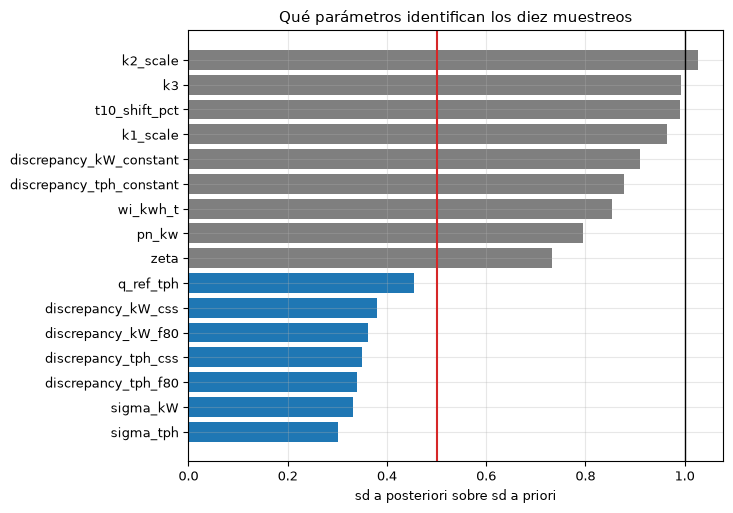

In [11]:

# Desviación estándar a posteriori sobre a priori de cada parámetro, del documento
fig, ax = plt.subplots(figsize=(7.4, 5.2))
names = [row["name"] for row in table]
values = [row["contraction"] for row in table]
ax.barh(names, values, color=["tab:blue" if v < 0.5 else "tab:grey" for v in values])
ax.axvline(0.5, color="tab:red", lw=1.5)
ax.axvline(1.0, color="black", lw=1)
ax.set_xlabel('sd a posteriori sobre sd a priori')
ax.set_title('Qué parámetros identifican los diez muestreos')
fig.tight_layout()
plt.show()


7 de los 16 parámetros quedan bajo 0.5: q_ref_tph, sigma_tph, sigma_kW, discrepancy_tph_css, discrepancy_tph_f80, discrepancy_kW_css, discrepancy_kW_f80. Son la base de capacidad (el único escalar que mueve el tonelaje, notebook 01), las dos escalas de ruido y las pendientes de discrepancia en la abertura y en el f80 de alimentación. Todo lo demás queda sobre 0.7, cerca de su a priori o apenas estrechado: `zeta` en 0.73, `wi_kwh_t` en 0.85, `pn_kw` en 0.80, y `k1_scale`, `k2_scale`, `k3` y `t10_shift_pct` en 0.96, 1.03, 0.99 y 0.99, las constantes de la discrepancia en 0.91 y 0.88. Los diez muestreos no determinan entonces las constantes de Andersen K1, K2 y K3 ni el desplazamiento de t10 de los modelos de clasificación y fractura: el a posteriori de esos escalares es su a priori, y una predicción que depende de ellos la lleva la discrepancia. Es un resultado sobre los datos, no un defecto del muestreador. La figura no muestra si más muestreos los identificarían; muestra que estos diez, que varían solo la abertura y el tamaño de alimentación, no lo hacen.

**El criterio de descarte.** La regla se aplica con la función del propio módulo, a partir de los puntajes y anchos de intervalo calculados en este notebook, término por término.

In [12]:

# El criterio de descarte del SDD, evaluado con la función del módulo sobre los números calculados
# arriba, redondeados como los redondea el cálculo (MAPE y anchos a dos decimales, cobertura a tres)
verdict = cb.kill_criterion(
    power_mape=round(cb_score["kW"]["mape"], 2), power_mape_blin=round(comparator_mape["kW"]["B_lin"], 2),
    tph_mape=round(cb_score["tph"]["mape"], 2), tph_mape_m0=round(comparator_mape["tph"]["M0"], 2),
    coverage={t: round(cb_score[t]["coverage"], 3) for t in cb.TARGETS},
    width={t: round(cb_score[t]["width"], 2) for t in cb.TARGETS},
    width_crushercal={t: round(float(np.mean(cc_band[t][1] - cc_band[t][0])), 2) for t in cb.TARGETS})
v = verdict
print(f"(a) MAPE de potencia {v['power_mape_pct']:.2f} % frente a B-lin {v['power_mape_blin_pct']:.2f} %: "
      f"ganancia {v['power_gain_over_blin_pts']:+.2f} puntos, se necesitan 3.0, "
      f"supera por el margen: {v['a_power_beats_blin_by_margin']}")
print(f"(a) MAPE de tonelaje {v['tph_mape_pct']:.2f} % frente al modelo base {v['tph_mape_m0_pct']:.2f} %: "
      f"ganancia {v['tph_gain_over_m0_pts']:+.2f} puntos, supera por el margen: {v['a_tph_beats_m0_by_margin']}")
print(f"(a) se cumple, es decir ninguno supera a su comparador por el margen: {v['a_holds']}")
print(f"(b) cobertura {v['coverage']}, fuera de 0.7 a 0.9: {v['coverage_outside_band']}")
print(f"(b) banda más ancha que la de CrusherCal: {v['band_wider_than_crushercal']}, "
      f"así que (b) se cumple: {v['b_holds']}")
print(f"veredicto: {v['verdict']}")


(a) MAPE de potencia 14.31 % frente a B-lin 12.78 %: ganancia -1.53 puntos, se necesitan 3.0, supera por el margen: False
(a) MAPE de tonelaje 12.00 % frente al modelo base 12.09 %: ganancia +0.09 puntos, supera por el margen: False
(a) se cumple, es decir ninguno supera a su comparador por el margen: True
(b) cobertura {'tph': 0.8, 'kW': 0.9}, fuera de 0.7 a 0.9: {'tph': False, 'kW': False}
(b) banda más ancha que la de CrusherCal: {'tph': False, 'kW': False}, así que (b) se cumple: False
veredicto: kept


La parte (a) de la regla se cumple: la ganancia de potencia sobre B-lin es -1.53 puntos, negativa, donde se habrían necesitado 9.78 por ciento (el 12.78 de B-lin menos el margen), y la ganancia de tonelaje sobre el modelo base es +0.09 puntos frente a los 3 exigidos. La parte (b) no se cumple: ambas coberturas quedan dentro de 0.7 a 0.9 y ambas bandas son más angostas que la de CrusherCal. La regla descarta el método solo cuando (a) y (b) se cumplen a la vez, así que el veredicto es **conservado** (kept en el documento): CrusherBayes permanece en el producto como predictor porque su intervalo es más estrecho que la banda de CrusherCal con una cobertura dentro de 0.7 a 0.9, aunque no supera a B-lin en la potencia y su intervalo es casi tan ancho como la banda de B-lin (117.7 frente a 119.6 kW). El veredicto descansa solo en la parte (b), y en su borde: la cobertura de potencia de 0.9 está en el límite superior inclusivo de 0.7 a 0.9, así que un muestreo más de diez dentro del intervalo de potencia daría 1.0, fuera de la banda, (b) se cumpliría y el método se descartaría. El criterio dice además que aun así la tabla de identificabilidad es el resultado, y esa es la sección de arriba. Sigue la única comprobación de reproducción del notebook: los puntajes, la ganancia de potencia y el veredicto recalculados aquí frente al documento versionado.

In [13]:

# La única comprobación de reproducción: los puntajes, la ganancia de potencia y el veredicto recalculados
# aquí frente al documento versionado
doc_kc = committed["kill_criterion"]
scores_equal = all(abs(cb_score[t]["mape"] - committed["loo"][t]["scores"]["mape_pct"]) < 0.01 for t in cb.TARGETS)
gain_equal = verdict["power_gain_over_blin_pts"] == doc_kc["power_gain_over_blin_pts"]
print(f"los puntajes igualan al documento: {scores_equal} | la ganancia de potencia iguala a la del documento "
      f"({doc_kc['power_gain_over_blin_pts']:+.2f}): {gain_equal} | el veredicto iguala al del documento "
      f"({doc_kc['verdict']}): {verdict['verdict'] == doc_kc['verdict']}")


los puntajes igualan al documento: True | la ganancia de potencia iguala a la del documento (-1.53): True | el veredicto iguala al del documento (kept): True


**Qué muestra el registro de convergencia.** Las cadenas versionadas son las más largas que corre el cálculo, y el documento registra para cada a posteriori si el muestreador pasó su propio diagnóstico, una cadena de al menos 50 tiempos de autocorrelación. La celda imprime ese registro.

In [14]:

# El registro de convergencia de las cadenas versionadas
print('a posteriori   tau [pasos]   cadena sobre tau   convergió')
for row in record:
    print(f"{row['fold']!s:9s} {row['tau_max']:12.1f} {row['chain_over_tau']:16.1f} {row['converged']!s:>11}")


a posteriori   tau [pasos]   cadena sobre tau   convergió
1                 52.6            114.1        True
2                 52.7            113.8        True
3                 54.7            109.7        True
4                 84.8             70.7        True
5                 52.7            113.9        True
6                 48.0            125.0        True
7                 55.1            108.9        True
8                 48.9            122.7        True
9                 52.6            114.1        True
10                50.7            118.3        True
all               48.6            123.5        True


Las 11 distribuciones a posteriori lo pasan: las cadenas de 7000 pasos tienen tiempos de autocorrelación de 48 a 85 pasos y largos de 70.7 a 125.0 veces eso, sobre las 50 que exige el pipeline, con los movimientos de evolución diferencial de ter Braak (2006) y de ter Braak y Vrugt (2008) que usa el muestreador (un cálculo anterior con el movimiento de estiramiento de Goodman y Weare (2010) no lo alcanzó). Los puntajes de arriba son entonces estimaciones de cadenas que pasaron el diagnóstico del propio muestreador. Es una afirmación sobre las cadenas y no una prueba de convergencia: el diagnóstico es un criterio, y diez muestreos dejan anchos a los parámetros débilmente identificados cualquiera sea el largo de la cadena, así que las razones de contracción cercanas a 1 significan que los datos no los restringen, no que el muestreador falló.

## Resultados

**Respuesta:** CrusherBayes no predice un muestreo retenido mejor que B-lin; sí da un intervalo más estrecho que la banda de CrusherCal con una cobertura dentro de 0.7 a 0.9, y el criterio lo conserva. Con retención en los diez muestreos tiene un error de potencia de 14.31 por ciento frente a 12.78 de B-lin (1.53 puntos detrás) y 25.94 del modelo base, y un error de tonelaje de 12.00 por ciento frente a 12.09 del modelo base, una ganancia de 0.09 puntos que diez muestreos no distinguen de cero. Sus intervalos de 80 por ciento tienen 118 kW y 439 t/h de ancho frente a 210 kW y 474 t/h de CrusherCal, con 9 y 8 muestreos de 10 dentro. Es una ganancia frente a la banda del modelo base, no frente a una recta: la banda anidada de B-lin en la potencia ya tiene 119.6 kW de ancho con cobertura 0.8, frente a 117.7 kW con cobertura 0.9 de CrusherBayes, un muestreo de diez de diferencia. Los muestreos identifican la base de capacidad (contracción 0.45), el ruido y las pendientes de discrepancia, y dejan K1, K2, K3 y el desplazamiento de t10 en su a priori (contracción 0.96 a 1.03). El criterio de descarte, recalculado aquí con los números del propio notebook, da el veredicto conservado que registra el documento, porque la parte (b) no se cumple, y por poco: la cobertura de potencia de 0.9 está en el borde de 0.7 a 0.9. Las cadenas pasaron su propio diagnóstico en 11 de las 11 distribuciones a posteriori, con 70.7 a 125.0 tiempos de autocorrelación.

## Resumen

CrusherBayes se mide aquí frente al criterio que se escribió antes de correrlo. Estrecha el intervalo predictivo del modelo base en la potencia de 210 a 118 kW y reduce el error de potencia del modelo base de 25.94 a 14.31 por ciento, pero el competidor más simple, una recta sobre la abertura, predice la potencia igual o mejor (12.78 por ciento) y ya da una banda casi igual de estrecha (119.6 kW con cobertura 0.8), y el método no afirma otra cosa. Lo que agrega y ningún ajuste puntual da es la tabla de identificabilidad: con diez muestreos de una máquina los datos dicen qué son la capacidad y el ruido y nada de las constantes de clasificación y fractura. El resultado se sostiene en cadenas que pasaron su diagnóstico de convergencia en las once distribuciones a posteriori, así que las razones de contracción se pueden citar como medidas, dentro de lo que diez muestreos pueden mostrar.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Kennedy, M. C., O'Hagan, A. (2001), Bayesian calibration of computer models, Journal of the Royal Statistical Society B 63(3), 425-464. https://doi.org/10.1111/1467-9868.00294
- ter Braak, C. J. F. (2006), A Markov chain Monte Carlo version of the genetic algorithm differential evolution: easy Bayesian computing for real parameter spaces, Statistics and Computing 16, 239-249. https://doi.org/10.1007/s11222-006-8769-1
- ter Braak, C. J. F., Vrugt, J. A. (2008), Differential evolution Markov chain with snooker updater and fewer chains, Statistics and Computing 18, 435-446. https://doi.org/10.1007/s11222-008-9104-9
- Goodman, J., Weare, J. (2010), Ensemble samplers with affine invariance, Communications in Applied Mathematics and Computational Science 5(1), 65-80. https://doi.org/10.2140/camcos.2010.5.65